# Cup and Cap Synchronization: theory examples

Companion notebook to *"Cup and cap synchronization: higher-order node dynamics from topology"* by R. Wang, Y. Zhang and G. Bianconi.

On fully connected networks the theory reduces the dynamics to a single self-consistent equation $\Lambda = F(\Lambda;\sigma_1,\sigma_2,\sigma_3)$ for the effective field $\Lambda$ (see the paper and the SI). All the functions are in [`cupcap.py`](cupcap.py). This notebook shows the two things the theory lets us do:

1. **Follow the transitions** by sweeping $\sigma_1$ up (synchronization) and down (desynchronization), including continuous, discontinuous and bias-dependent transitions.
2. **Design the phase diagram** in the $(\sigma_1,\sigma_2)$ plane: pitchfork line, saddle-node curve and cusp.

All examples use Gaussian intrinsic frequencies, $\omega\sim\mathcal N(0,1)$. The whole notebook runs in about 5 minutes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupcap as cc

plt.rcParams.update({"font.size": 14, "axes.labelsize": 17, "legend.fontsize": 12})
sigma1 = np.linspace(-10, 10, 401)     # sweep grid used for all transitions

A model is defined by the exponents $h_1, h_2$ of $f_r(x)=(\cos x)^{h_r-1}$, the four-body coupling $\sigma_3$ ($\sigma_3=0$ gives $M=2$), the frequency distribution $g$, and the bias $\eta$ of the initial synchronized state:

```python
cc.CupCap(h1=5)                                 # M = 2
cc.CupCap(h1=5, h2=2, sigma3=5, eta=0.8)        # M = 3, biased
```

`cc.follow_transition(model, sigma1, sigma2)` returns $R_1$ along the synchronization path (starting from the incoherent state) and the desynchronization path (starting from a synchronized state with bias $\eta$).

---
## 1. Following the transitions

### 1.1 Continuous and discontinuous transitions ($M=2$, $h=5$)

For odd $h$, the same model has a continuous transition below the cusp ($\sigma_2=-5$) and a discontinuous transition with a stable hysteresis loop above it ($\sigma_2=10$), as in main text Fig. 4(b,d).

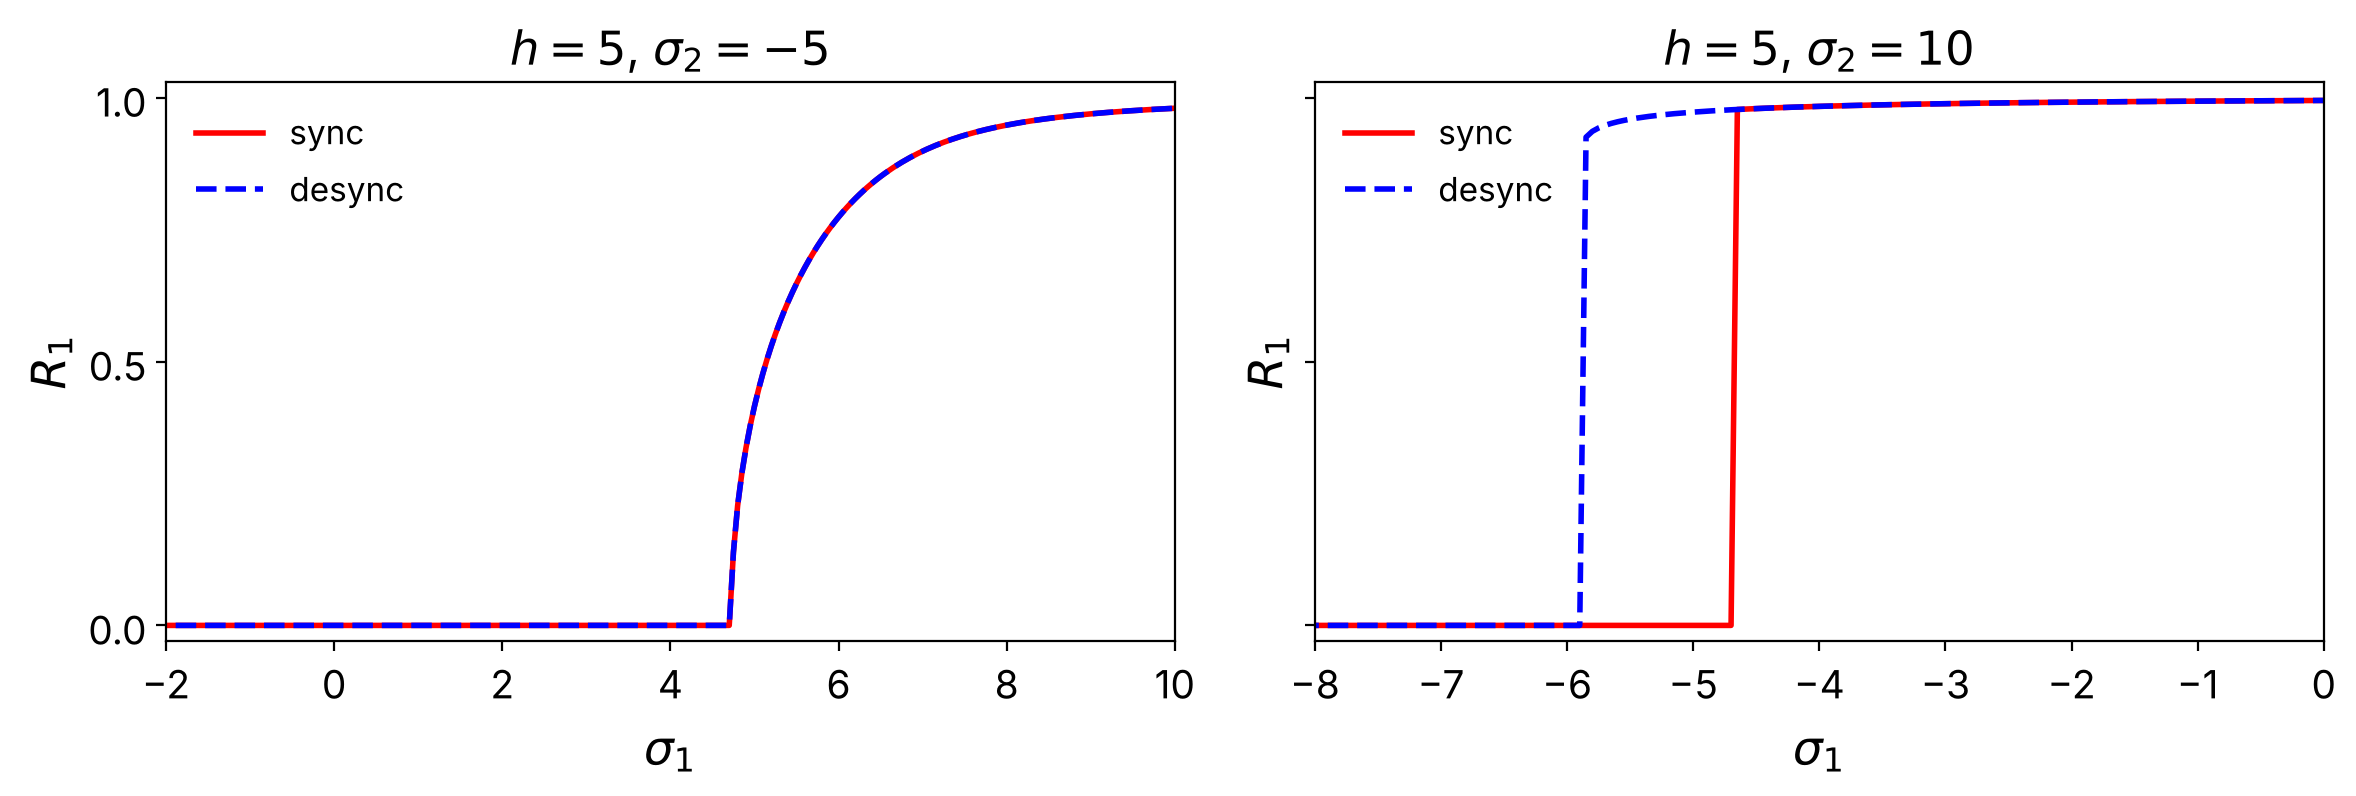

In [2]:
model = cc.CupCap(h1=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, sigma2, xlim in zip(axes, (-5, 10), ((-2, 10), (-8, 0))):
    r = cc.follow_transition(model, sigma1, sigma2)
    cc.plot_transition(ax, sigma1, [(r["sync"], "sync", "red", "-"),
                                    (r["desync"], "desync", "blue", "--")],
                       xlim=xlim, title=rf"$h=5$, $\sigma_2={sigma2}$")
plt.tight_layout()
plt.show()

### 1.2 Bias-dependent desynchronization ($M=2$, $h=4$, $\sigma_2=3$)

For even $h$, half-integer order parameters enter the dynamics. Synchronization starts from the unbiased incoherent state and is always continuous. Desynchronization depends on the bias $\eta$ of the initial state and becomes abrupt as $|\eta-1/2|$ grows (main text Fig. 4(a,c)).

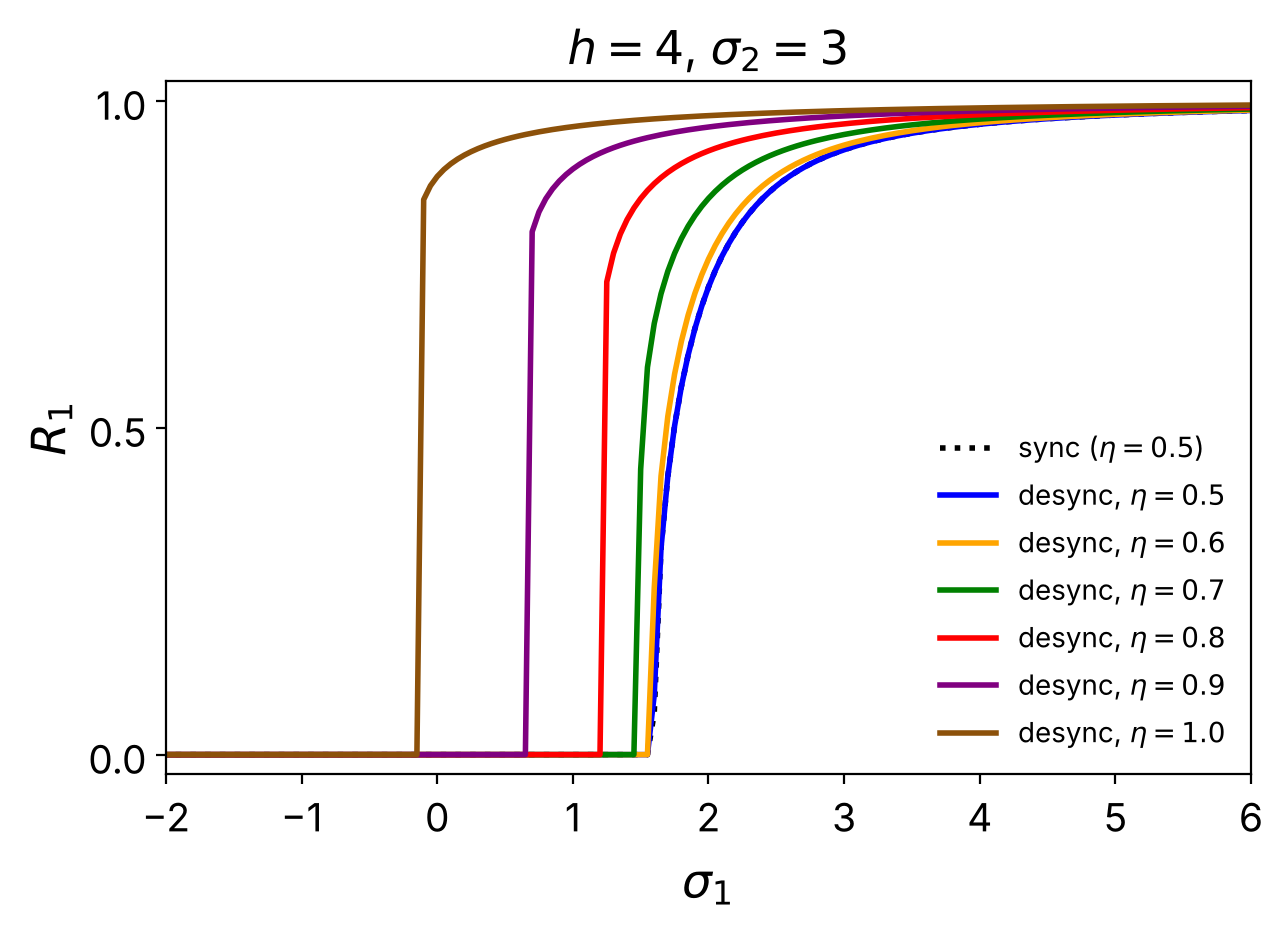

In [3]:
etas = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
model = cc.CupCap(h1=4)

curves = [(cc.follow_transition(model, sigma1, 3, desync=False)["sync"], r"sync ($\eta=0.5$)", "black", ":")]
for eta in etas:
    r = cc.follow_transition(cc.CupCap(h1=4, eta=eta), sigma1, 3, sync=False)
    curves.append((r["desync"], rf"desync, $\eta={eta}$", cc.ETA_COLORS[eta], "-"))

fig, ax = plt.subplots(figsize=(7, 4.5))
cc.plot_transition(ax, sigma1, curves, xlim=(-2, 6), title=r"$h=4$, $\sigma_2=3$")
ax.legend(frameon=False, fontsize=10)
plt.show()

### 1.3 Four-body interactions: hysteresis *and* bias ($M=3$, $h_1=5$, $h_2=2$, $\sigma_3=5$)

With $h_1$ odd and $h_2$ even, the three-body term gives a hysteresis loop and the four-body term makes desynchronization depend on the bias. Below are three values of $\sigma_2$: above, at and below the cusp $\sigma_2^C\simeq2.6$ (main text Fig. 7).

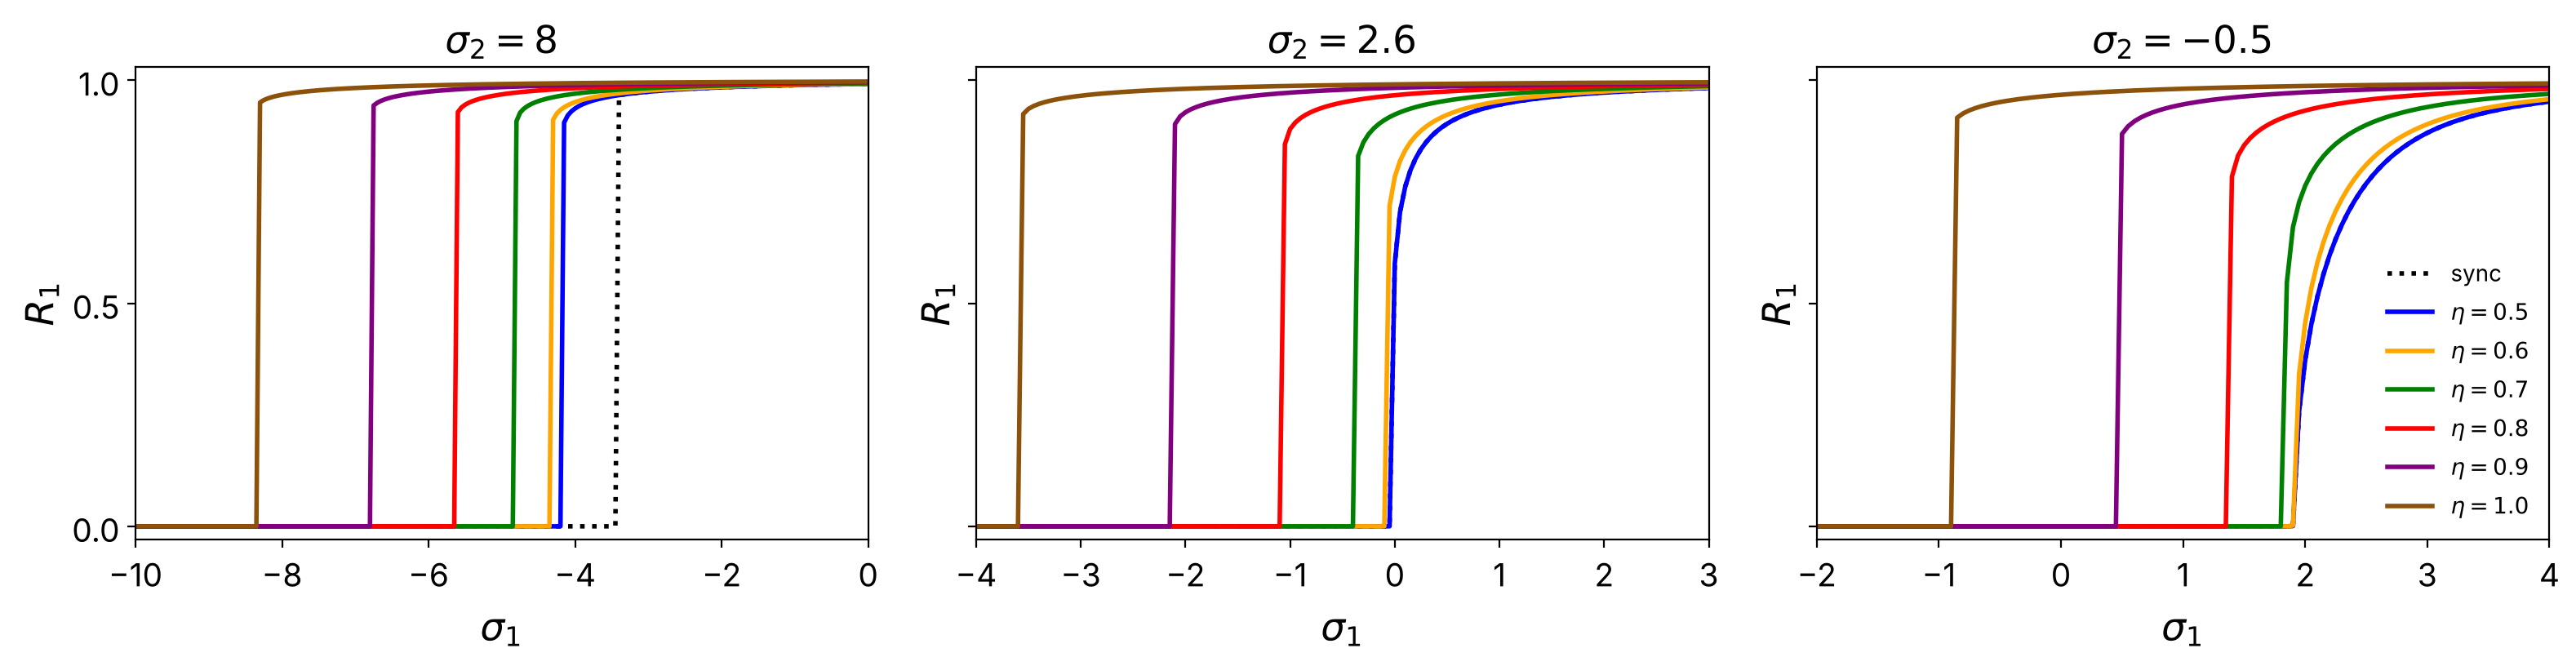

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, sigma2, xlim in zip(axes, (8, 2.6, -0.5), ((-10, 0), (-4, 3), (-2, 4))):
    curves = [(cc.follow_transition(cc.CupCap(5, 2, 5.0), sigma1, sigma2, desync=False)["sync"],
               "sync", "black", ":")]
    for eta in etas:
        r = cc.follow_transition(cc.CupCap(5, 2, 5.0, eta=eta), sigma1, sigma2, sync=False)
        curves.append((r["desync"], rf"$\eta={eta}$", cc.ETA_COLORS[eta], "-"))
    cc.plot_transition(ax, sigma1, curves, xlim=xlim, title=rf"$\sigma_2={sigma2}$")
    ax.legend().remove()
axes[-1].legend(frameon=False, fontsize=10, loc="lower right")
plt.tight_layout()
plt.show()

---
## 2. Designing the phase diagram

`cc.phase_diagram(model)` finds the bifurcations of $\Lambda=F(\Lambda)$:

* the **pitchfork line** $F'(0)=1$, split into subcritical and supercritical parts;
* the **saddle-node curve**, where a synchronized solution appears ($F(\Lambda^\star)=\Lambda^\star$, $F'(\Lambda^\star)=1$);
* the **cusp**, where the two meet;
* for biased dynamics, the **grey point** where the desynchronization transition becomes continuous.

Shaded regions: incoherent, synchronized, and bistable (hysteresis).

### 2.1 $M=2$, $h=3$ and $h=5$ (main text Fig. 3(e,f))

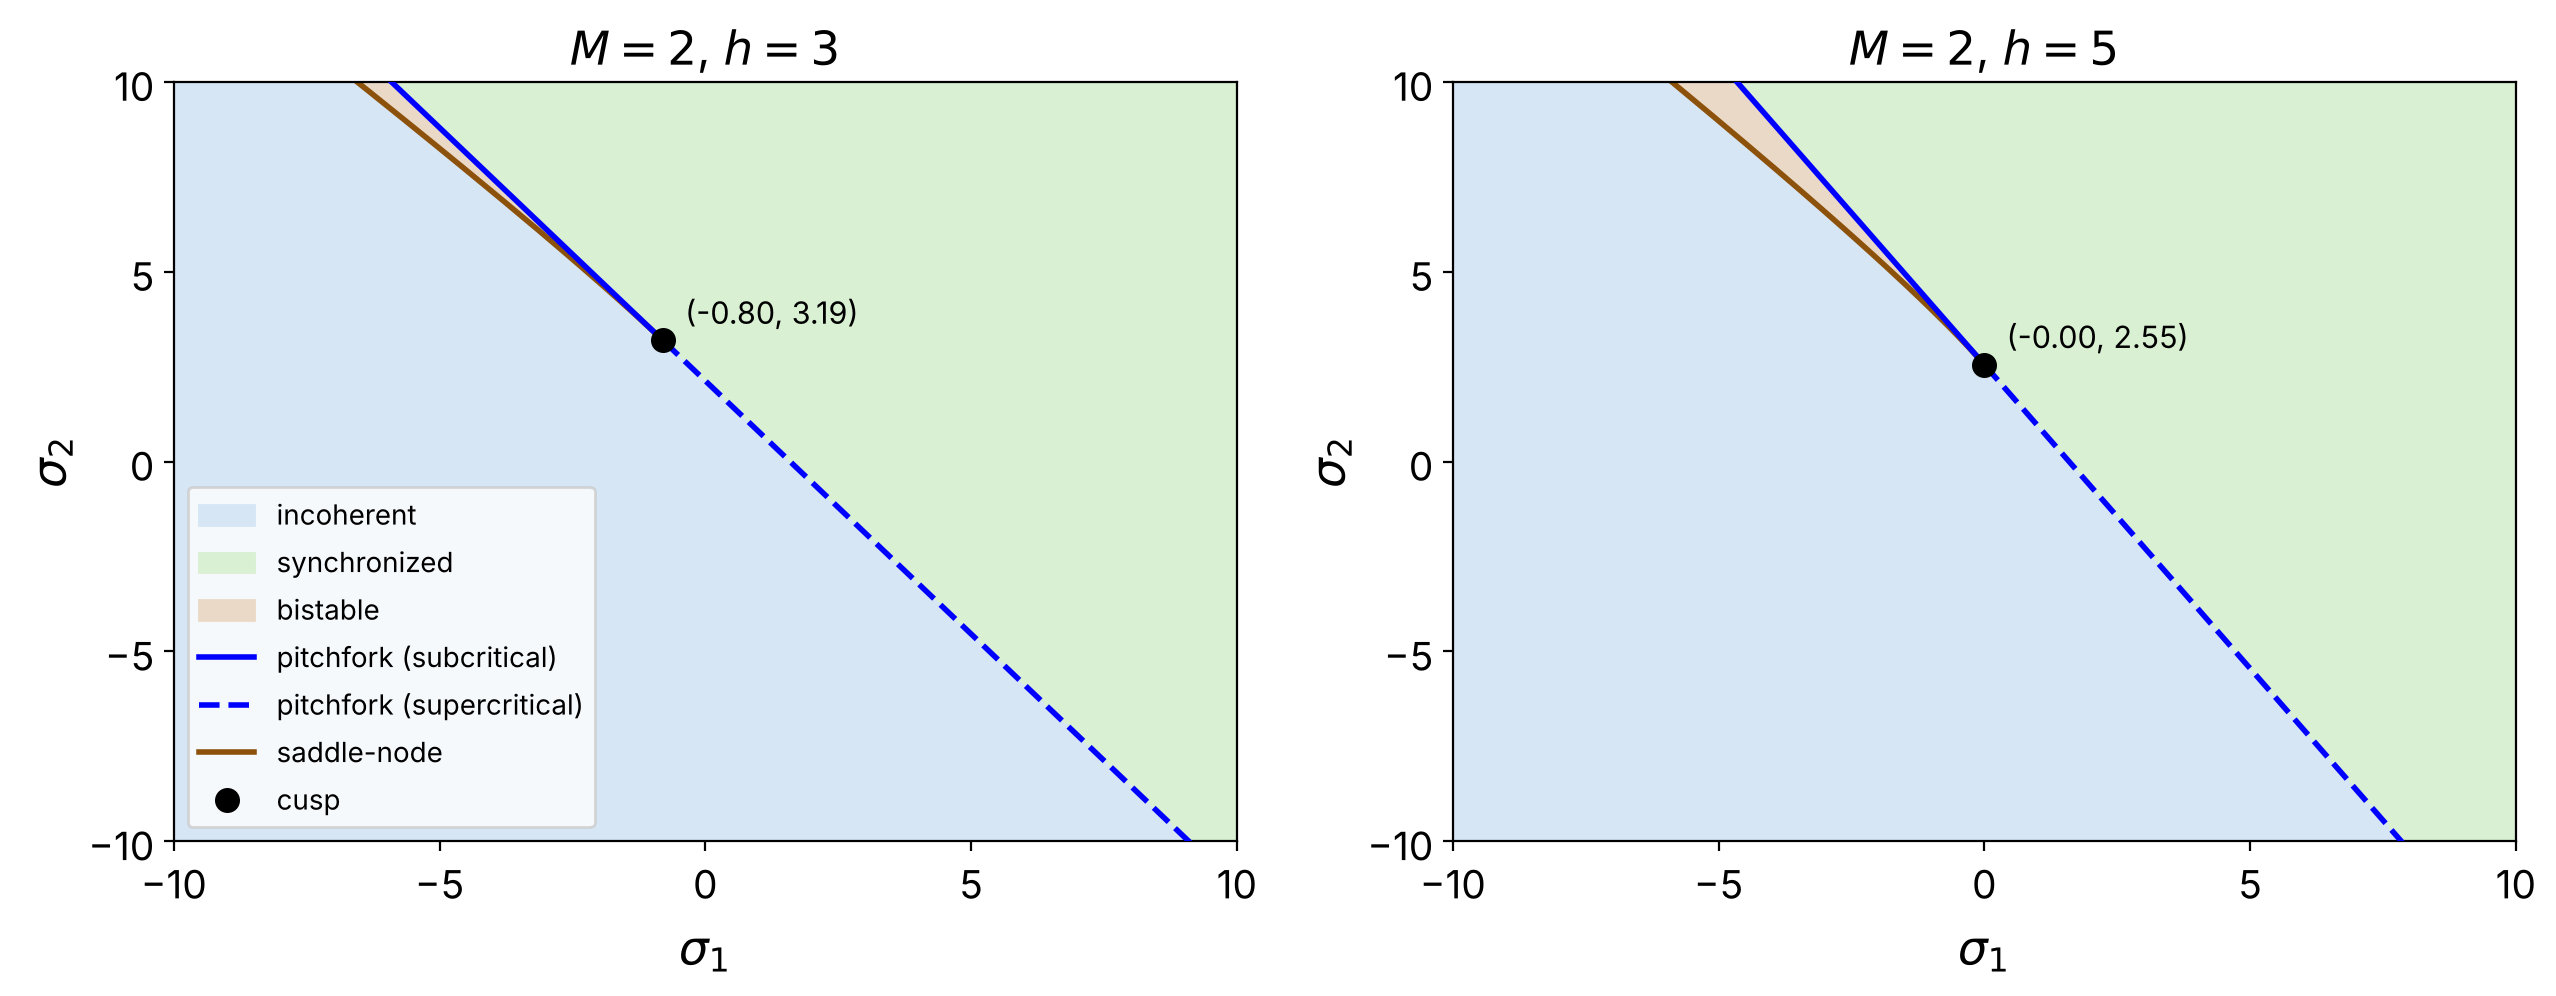

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, h in zip(axes, (3, 5)):
    pd = cc.phase_diagram(cc.CupCap(h1=h))
    cc.plot_phase_diagram(ax, pd)
    ax.set_title(rf"$M=2$, $h={h}$")
axes[0].legend(loc="lower left", fontsize=10)
plt.tight_layout()
plt.show()

### 2.2 $M=3$, $h_1=5$, $h_2=2$, $\sigma_3=5$ (main text Fig. 6)

The pitchfork line does not depend on the bias, but the saddle-node curve does. The shading shows the unbiased case, $\eta=0.5$. Brown curves, from light to dark, are the saddle-node curves for $\eta=0.5,\dots,1$, and the grey dots mark where the desynchronization transition with bias $\eta$ becomes continuous.

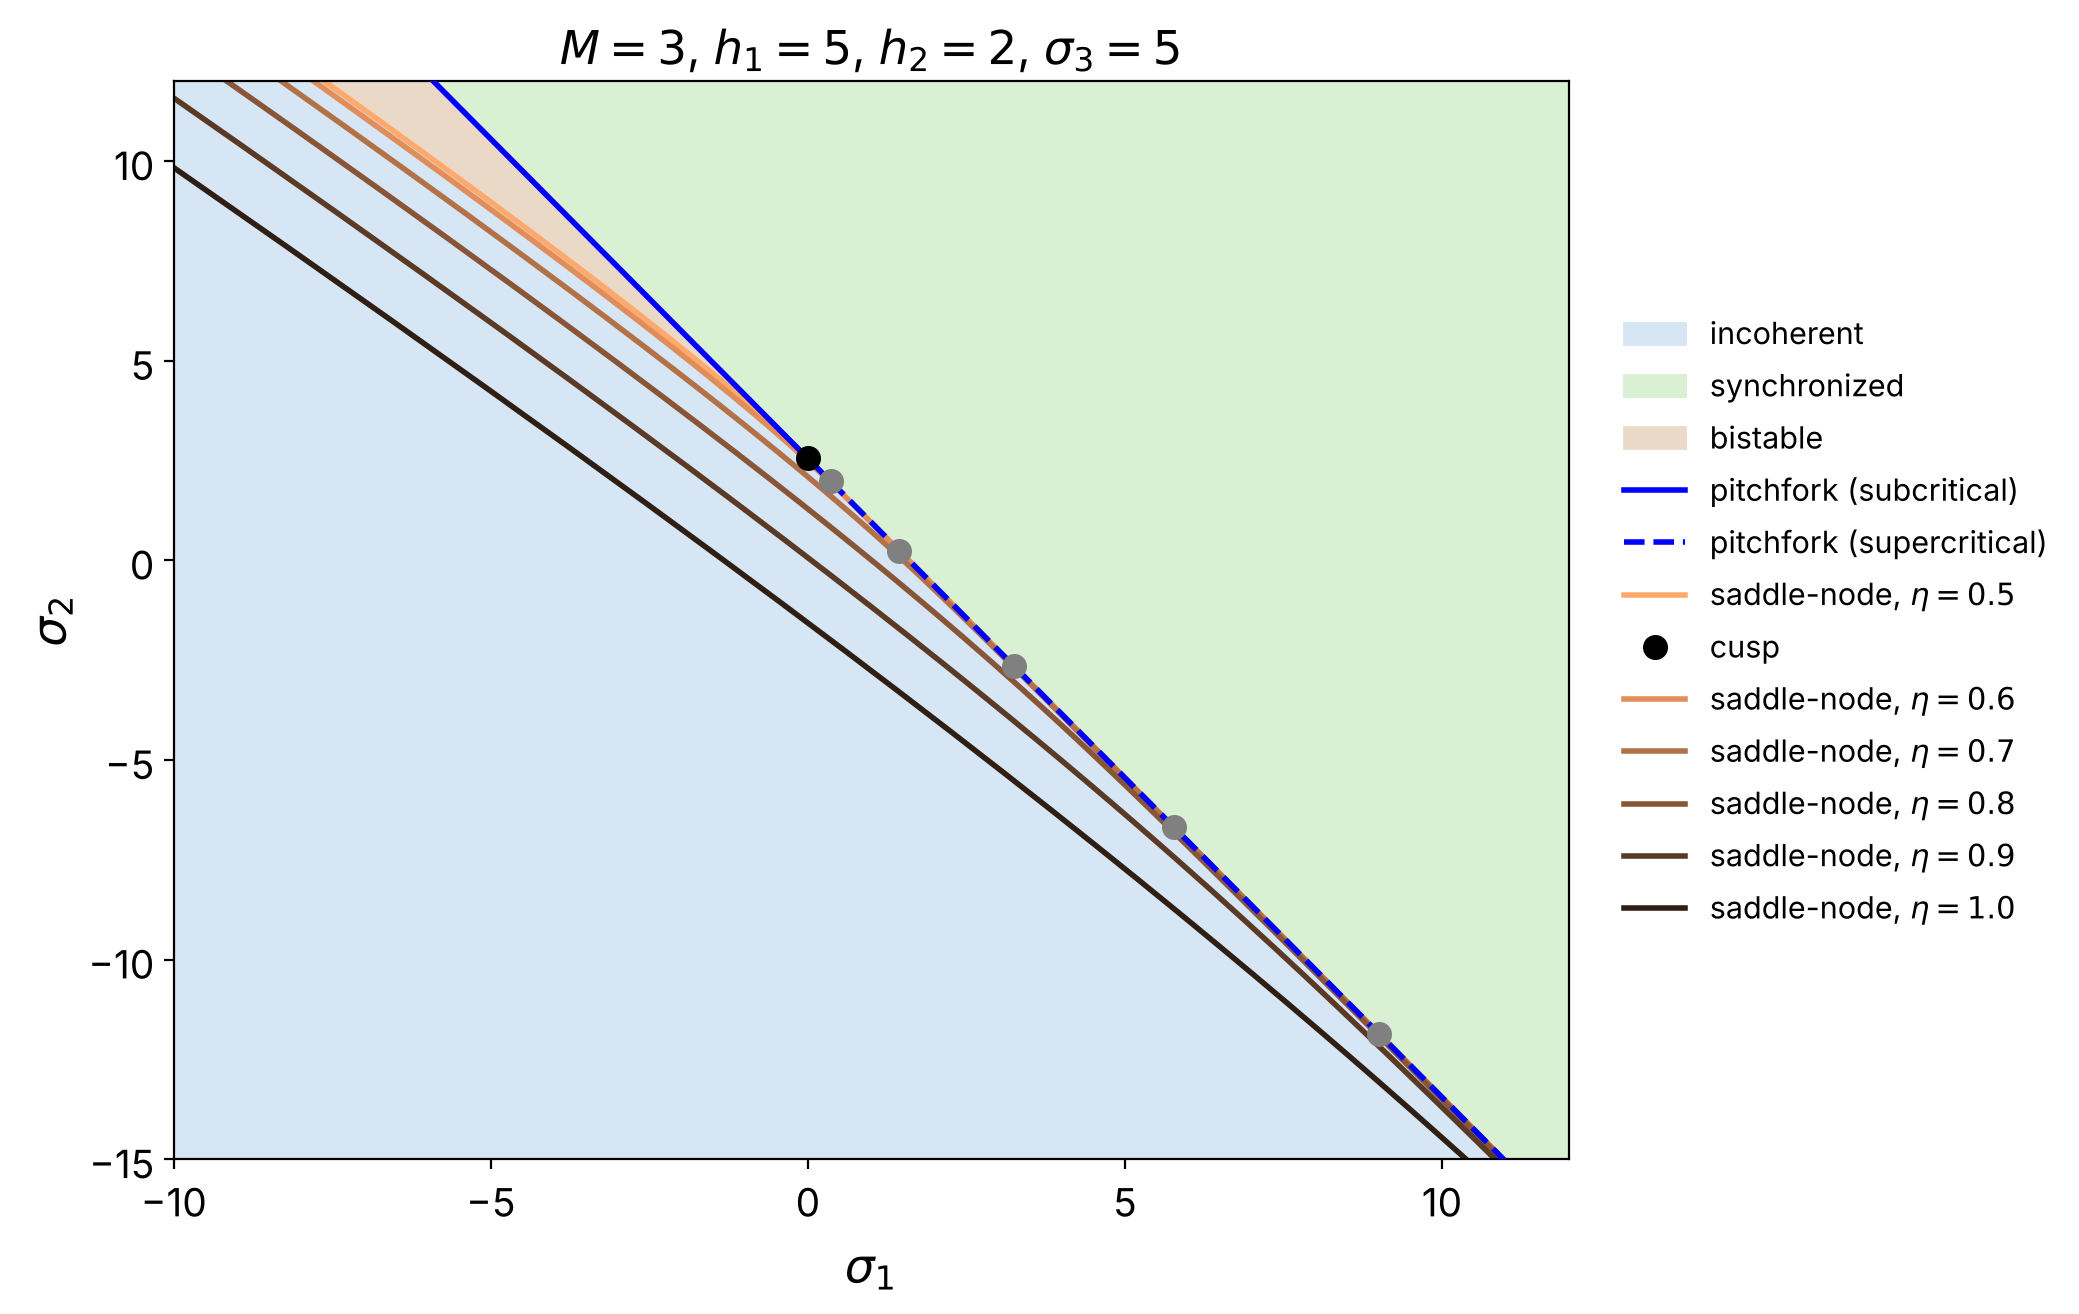

eta   cusp / grey point
0.5   (-0.00,   2.55)
0.6   ( 0.36,   1.98)
0.7   ( 1.44,   0.25)
0.8   ( 3.24,  -2.64)
0.9   ( 5.77,  -6.68)
1.0   ( 9.01, -11.87)


In [6]:
browns = plt.cm.copper_r(np.linspace(0.15, 0.85, len(etas)))
xlim, ylim = (-10, 12), (-15, 12)

fig, ax = plt.subplots(figsize=(9, 7))
diagrams = {eta: cc.phase_diagram(cc.CupCap(5, 2, 5.0, eta=eta), sigma1_range=xlim) for eta in etas}
for i, (eta, pd) in enumerate(diagrams.items()):
    cc.plot_phase_diagram(ax, pd, xlim, ylim, shade=(i == 0), show_pitchfork=(i == 0),
                          sn_color=browns[i], sn_label=rf"saddle-node, $\eta={eta}$", annotate=False)
ax.set_title(r"$M=3$, $h_1=5$, $h_2=2$, $\sigma_3=5$")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=11, frameon=False)
plt.show()

print("eta   cusp / grey point")
for eta, pd in diagrams.items():
    point = pd.cusp if pd.cusp is not None else pd.grey
    print(f"{eta:.1f}   ({point[0]:5.2f}, {point[1]:6.2f})")

These values match those reported in the caption of Fig. 6: cusp at $(0, 2.6)$, and grey points at $(0.36, 1.98)$, $(1.44, 0.25)$, $(3.24, -2.64)$, $(5.77, -6.68)$ and $(9.01, -11.87)$.

### 2.3 Try your own

Change the model below. As a check, for a Lorentzian $g(\omega)$ the theory gives the cusp at $(-2, 32/5)$ for $h=5$ (SI Table I).

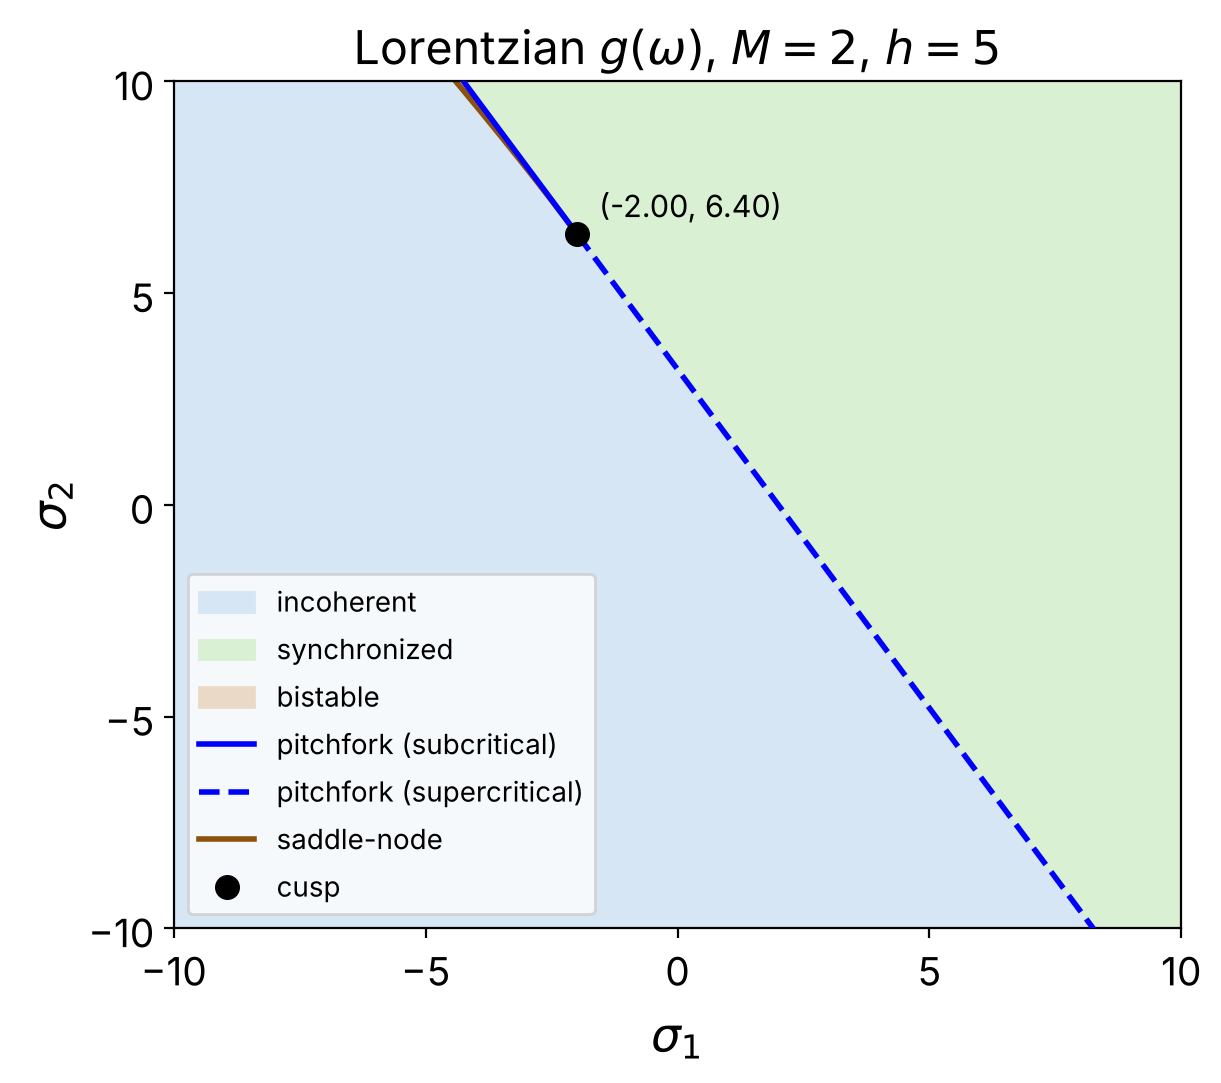

In [7]:
model = cc.CupCap(h1=5, g=cc.g_lor)        # e.g. cc.CupCap(h1=3, h2=4, sigma3=-2, eta=0.7)

pd = cc.phase_diagram(model)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
cc.plot_phase_diagram(ax, pd)
ax.set_title("Lorentzian $g(\\omega)$, $M=2$, $h=5$")
ax.legend(loc="lower left", fontsize=10)
plt.show()